# Compute the potential-field data

Compute the potential-field data produced by the geological source simulated in the notebook `1_model.ipynb`.

### Things we have to import

In [1]:
import numpy as np

In [2]:
import matplotlib.pyplot as plt

In [3]:
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

In [4]:
import time

In [5]:
import pickle

In [6]:
from gravmag import data_structures, utils, aux_vedo, constants
from gravmag.models import rectangular_prism as rp

In [7]:
import vedo

In [8]:
# set the backend for vedo
vedo.settings.default_backend= 'vtk'
#vedo.settings.default_backend= '2d'

### Set path for saving figures

In [9]:
figures = '../manuscript/figures/'

### Load the model

In [10]:
boundary_points = pickle.load(open('model/1_model_boundary_points.pickle', 'rb'))

In [11]:
# append the first point at the end to plot a closed curve
boundary_points = np.vstack([boundary_points, boundary_points[0]])

In [12]:
model = pickle.load(open('model/1_model.pickle', 'rb'))

In [13]:
model_area = pickle.load(open('model/1_model_area.pickle', 'rb'))
model_shape = pickle.load(open('model/1_model_shape.pickle', 'rb'))

In [14]:
mag_intensity = pickle.load(open('model/1_model_mag_intensity.pickle', 'rb'))
mag_inc = pickle.load(open('model/1_model_mag_inc.pickle', 'rb'))
mag_dec = pickle.load(open('model/1_model_mag_dec.pickle', 'rb'))

In [15]:
# Cartesian components of the model magnetization
v_hat = utils.unit_vector(inc=mag_inc[0], dec=mag_dec[0])

In [16]:
# compute a normalized horizontal projection of v_hat to plot
v_hat_horizontal = v_hat[:2]/np.linalg.norm(v_hat[:2])

In [17]:
# model properties
print("(xmin, xmax) = ({:.3f}, {:.3f}) m".format(model['x1'].min(), model['x2'].max()))
print("(ymin, ymax) = ({:.3f}, {:.3f}) m".format(model['y1'].min(), model['y2'].max()))
print("(top min, top max) = ({:.3f}, {:.3f}) m".format(model['z1'].min(), model['z1'].max()))
print("(bottom min, bottom max) = ({:.3f}, {:.3f}) m".format(model['z2'].min(), model['z2'].max()))
print("number of prisms: {}".format(model['x1'].size))

(xmin, xmax) = (-3600.986, 4900.000) m
(ymin, ymax) = (-3000.333, 5800.167) m
(top min, top max) = (0.000, 300.000) m
(bottom min, bottom max) = (300.001, 600.001) m
number of prisms: 1241


In [18]:
# compute the Cartesian components of magnetization
mx, my, mz = utils.magnetization_components(
    np.vstack([mag_intensity, mag_inc, mag_dec]).T
)

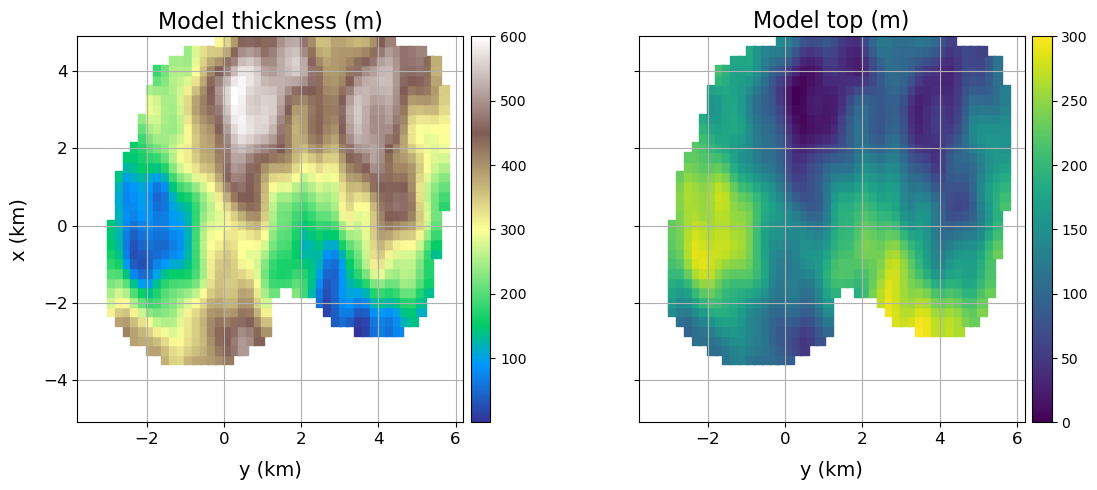

In [19]:
fig, axs = plt.subplots(
    ncols=2, nrows=1, 
    sharex=False, sharey=True,
    figsize=(12, 5), 
)

axs[0].set_title("Model thickness (m)", fontsize=16)
axs[0].axis('scaled')
image = axs[0].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z2']-model['z1'],
    marker='s',
    cmap='terrain'
)
axs[0].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[0].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[0].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[0])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[0].grid()
axs[0].set_ylabel('x (km)', fontsize=14, labelpad=10)
axs[0].set_xlabel('y (km)', fontsize=14, labelpad=10)

axs[1].set_title("Model top (m)", fontsize=16)
axs[1].axis('scaled')
image = axs[1].scatter(
    x=0.5*(model['y1']+model['y2'])*0.001, 
    y=0.5*(model['x1']+model['x2'])*0.001, 
    s=50,
    c=model['z1'],
    marker='s',
    cmap='viridis'
)
axs[1].set_ylim(0.001*model_area[0], 0.001*model_area[1])
axs[1].set_xlim(0.001*model_area[2], 0.001*model_area[3])
axs[1].tick_params(axis='both', labelsize=12)
ax_divider = make_axes_locatable(axs[1])
cax = ax_divider.append_axes("right", size="5%", pad="2%")
cb = fig.colorbar(image, cax=cax)
axs[1].grid()
axs[1].set_xlabel('y (km)', fontsize=14, labelpad=10)

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.30, hspace=0.05)

plt.tight_layout()

plt.show()

### 3D Plot

In [20]:
# create a Vedo model of prisms with colors defined by the total-magnetization intensity
model_vedo = aux_vedo.gravmag2vedo_prisms(
    gravmag_prisms=model,
    scalar_props=mag_intensity,
    cmap='jet',
    vmin=np.min(mag_intensity),
    vmax=np.max(mag_intensity)
)


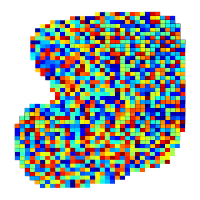

In [21]:
# add a colorbar to the prisms
model_vedo.add_scalarbar(
    title='magnetization (A/m)', 
    pos=(0.8,0.01),
    title_yoffset=15,
    font_size=14,
    nlabels=10,
    horizontal=False,
    label_format=':6.2f'
)

### Main field

In [22]:
main_field = pickle.load(open('model/2_main_field.pickle', 'rb'))

In [23]:
# Cartesian components of the main field
F_hat = utils.unit_vector(inc=main_field['inc'], dec=main_field['dec'])

In [24]:
# compute a normalized horizontal projection of F_hat to plot
F_hat_horizontal = F_hat[:2]/np.linalg.norm(F_hat[:2])

### Points were we compute the synthetic data

In [25]:
# number of points along x and y
data_shape = (400, 330)
print('n. data = {}'.format(data_shape[0]*data_shape[1]))

# minimum x, maximum x, minimum y and maximum y
data_area = [-7100, 7500, -4800, 7200]

# grid spacing
data_dx, data_dy = data_structures.grid_xy_spacing(area=data_area, shape=data_shape)
print('dx = {:.3f} m | dy = {:.3f} m'.format(data_dx, data_dy))

n. data = 132000
dx = 36.591 m | dy = 36.474 m


In [26]:
coordinates_grid = pickle.load(open('model/2_coordinates_grid.pickle', 'rb'))

In [27]:
print('num. data points = {}'.format(coordinates_grid['shape'][0]*coordinates_grid['shape'][1]))

num. data points = 132000


### Synthetic data

In [28]:
simulated_fields = dict()

In [29]:
simulated_fields = pickle.load(open('model/2_simulated_fields.pickle', 'rb'))

# Plot the data

In [30]:
# coordinates rearranged for plotting
# they are "views' of the original coordinates in 'coordinates_grid'
X, Y = data_structures.grid_xy_to_full_matrices_view(
    x = coordinates_grid['x'],
    y = coordinates_grid['y'],
    shape = coordinates_grid['shape']
)

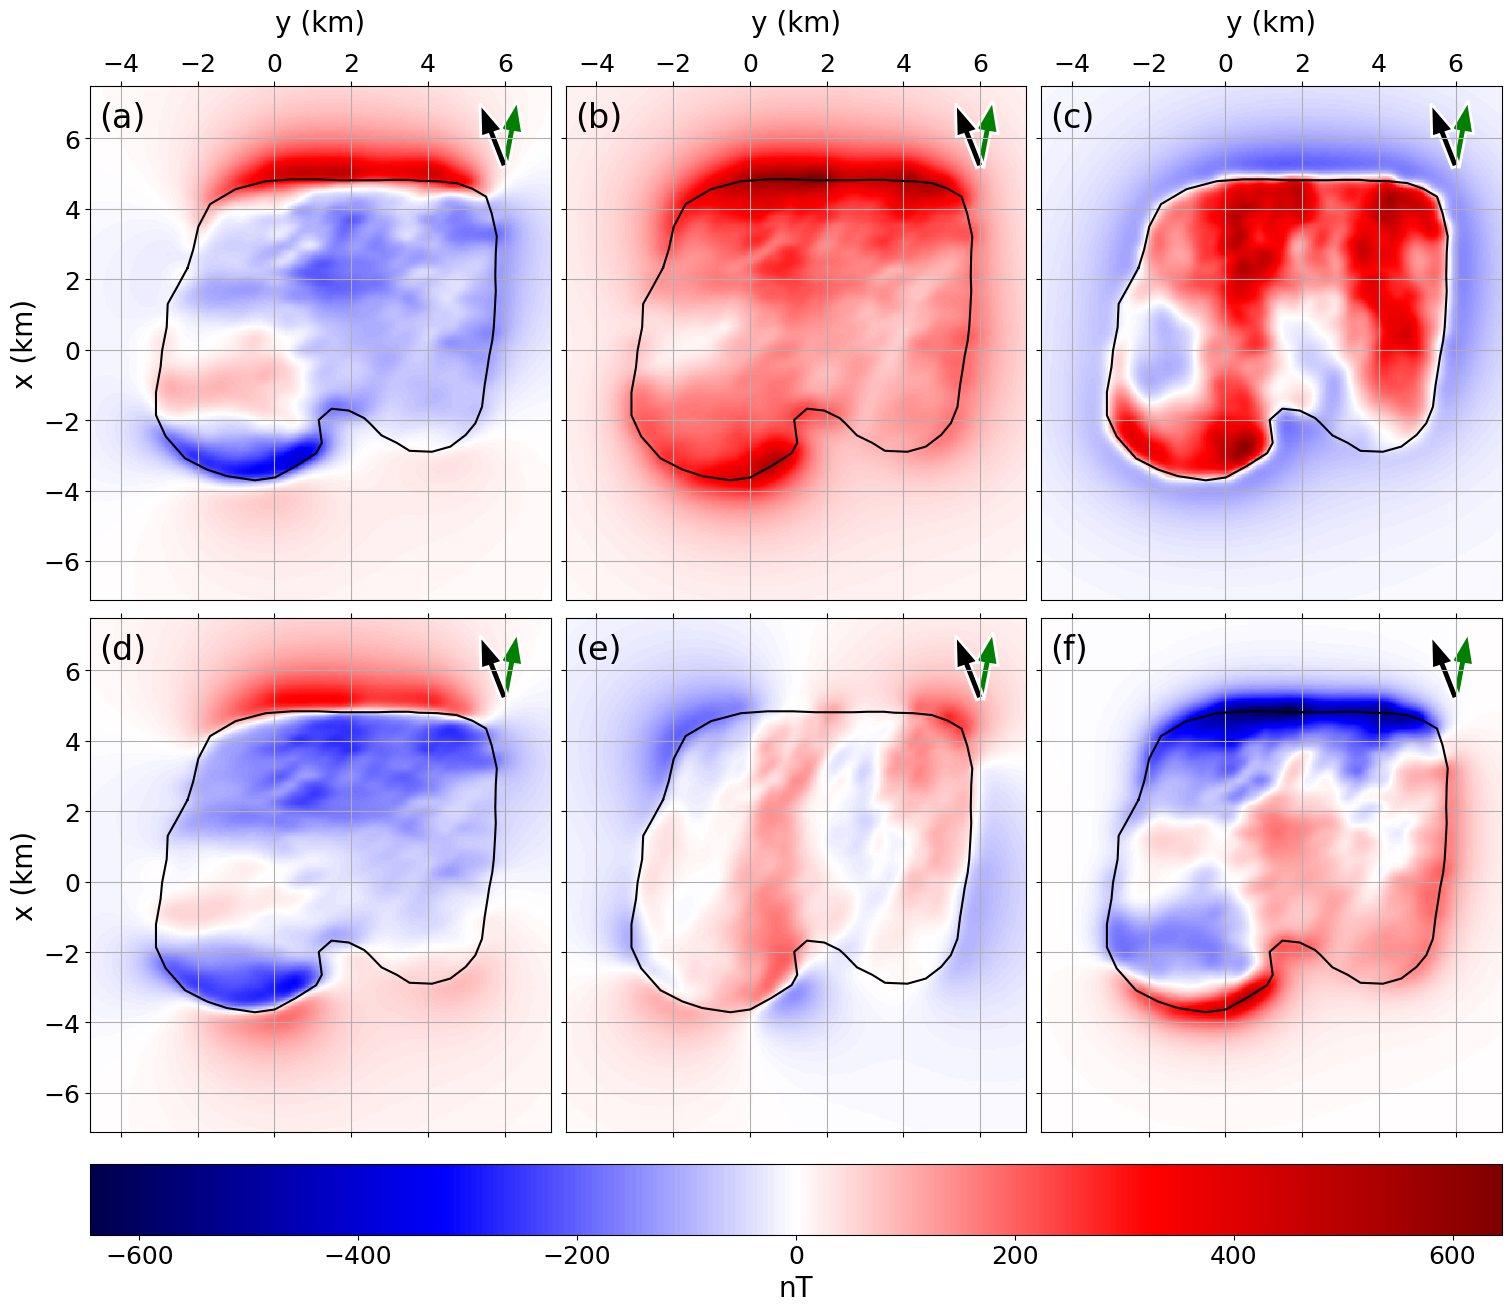

In [31]:
# plot figure
fig = plt.figure(
    layout= 'constrained', 
    figsize=(15,13)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             def
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']

mosaic_elements = ['a', 'b', 'c', 'd', 'e', 'f']

titles = [
    'Approx. TFA', 'Amplitude B', 'RTP', 
    'Bx', 'By', 'Bz'
]

units = 6*['nT']

ranges_b = np.max(np.abs(
    [
        simulated_fields['atfa'],
        simulated_fields['b'], 
        simulated_fields['rtp'], 
        simulated_fields['bx'], 
        simulated_fields['by'], 
        simulated_fields['bz'], 
    ]
))

ranges = 6*[ranges_b]

for (element, field, label, ranges_field, unit, title) in zip(
    mosaic_elements, 
    ['atfa', 'b', 'rtp', 'bx', 'by', 'bz'], 
    labels,
    ranges,
    units,
    titles
):
    ax = mosaic[element]
    #ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=simulated_fields[field],
            grid_orientation='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_field, vmax=ranges_field
    )
    # ax_divider = make_axes_locatable(ax)
    # cax = ax_divider.append_axes("right", size="3%", pad="2%")
    # cb = fig.colorbar(im, cax=cax)
    # cb.ax.tick_params(labelsize=14)
    # cb.ax.set_xlabel(unit, fontsize=16, loc='left')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.92), xycoords='axes fraction', fontsize=24)
    # ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
    ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='green', ec='white') 
    ax.arrow(x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, fc='black', ec='white') 

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.10)
    
for element in ['a','d']:
    mosaic[element].set_ylabel('x (km)', fontsize=20)
for element in ['a','b','c']:
    mosaic[element].tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
    mosaic[element].set_xlabel('y (km)', fontsize=20, loc='center', labelpad=15)
    mosaic[element].xaxis.set_label_position('top')
for element in ['d','e', 'f']:
    mosaic[element].tick_params(top=True, bottom=True, labelbottom=False)

cb = fig.colorbar(
    mosaic['c'].collections[0], 
    ax=[mosaic['d'], mosaic['e'], mosaic['f']], 
    location='bottom'
)
cb.ax.tick_params(labelsize=18)
cb.ax.set_xlabel('nT', fontsize=20, loc='center')
    
plt.savefig(figures+'Figure2_3.png', dpi=300)

plt.show()

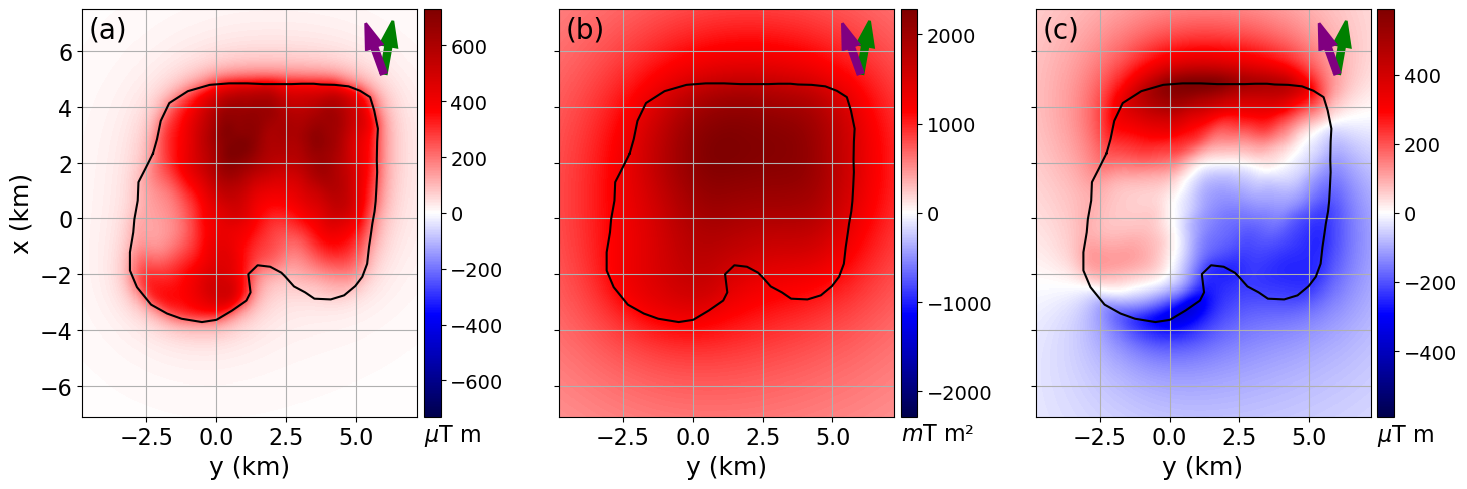

In [32]:
# plot figure
fig = plt.figure(
    layout= 'tight', 
    figsize=(15,5)
)
mosaic = fig.subplot_mosaic(
    mosaic = '''
             abc
             ''',
    sharex=True, sharey=True
)

labels = ['(a)', '(b)', '(c)']

mosaic_elements = ['a', 'b', 'c']

titles = [
    'Pseudo gz', 'Pseudo U', 'Mag. scalar potential V'
]

units = ['$\mu$T m'] + ['$m$T m²'] + ['$\mu$T m']


ranges_pseudo_grav = np.max(np.abs(simulated_fields['gz']))
ranges_U = np.max(np.abs(simulated_fields['U']))
ranges_V = np.max(np.abs(simulated_fields['V']))
ranges = [ranges_pseudo_grav] + [ranges_U] + [ranges_V]

for (element, field, label, ranges_field, unit, title) in zip(
    mosaic_elements, 
    ['gz', 'U', 'V'], 
    labels,
    ranges,
    units,
    titles
):
    ax = mosaic[element]
    ax.axis('scaled')
    im = ax.pcolormesh(
        Y*0.001, X*0.001, 
        data_structures.grid_xy_full_flatten_to_matrix(
            data=simulated_fields[field],
            grid_orientation='xy',
            shape=coordinates_grid['shape']
        ),
        cmap='seismic', vmin=-ranges_field, vmax=ranges_field
    )
    ax_divider = make_axes_locatable(ax)
    cax = ax_divider.append_axes("right", size="5%", pad="2%")
    cb = fig.colorbar(im, cax=cax)
    cb.ax.tick_params(labelsize=14)
    cb.ax.set_xlabel(unit, fontsize=16, loc='left')
    ax.plot(boundary_points[:,1]*0.001, boundary_points[:,0]*0.001, 'k-')
    ax.set_ylim(0.001*coordinates_grid['area'][0], 0.001*coordinates_grid['area'][1])
    ax.set_xlim(0.001*coordinates_grid['area'][2], 0.001*coordinates_grid['area'][3])
    ax.tick_params(axis='x', labelsize=16)
    ax.tick_params(axis='y', labelsize=16)
    ax.grid()
    ax.annotate(label, xy=(0.02, 0.93), xycoords='axes fraction', fontsize=20)
    # ax.annotate(title, xy=(0.02, 0.03), xycoords='axes fraction', fontsize=14)
    ax.arrow(x=6, y=5.2, dx=F_hat_horizontal[1], dy=F_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='green') 
    ax.arrow(x=6, y=5.2, dx=v_hat_horizontal[1], dy=v_hat_horizontal[0], 
             width=0.2, length_includes_head=False, head_width=0.6, linewidth=2, color='purple') 

# set vertical and horizontal spaces between subplots
#fig.subplots_adjust(wspace=0.20, hspace=0.30)
    
for element in ['a']:
    mosaic[element].set_ylabel('x (km)', fontsize=18)
for element in ['a','b','c']:
    mosaic[element].set_xlabel('y (km)', fontsize=18)  

plt.show()